# Using TRIBEv2 to simulate brain responses to two experimental conditions
Simply provide a stimulus file with one column of (text) stimuli and another column of condition information (example below).

| stimulus | condition |
| -------- | --------- |
| DOG | ANIMATE |
| SHOE | INANIMATE |
| SINK | INANIMATE |
| BIRD | ANIMATE |
| $\vdots$ | $\vdots$ |

A brain response for each stimulus will be generated using TRIBEv2. These will then be compared (coarsely) based on the conditions to which each brain response belongs.

<font color="red"><b>WARNING:</b></font> This notebook will not run until you have received acces to the Llama-3.2 model using your HuggingFace account. You can do that [here](https://huggingface.co/meta-llama/Llama-3.2-3B).

In [2]:
# @title Install TRIBEv2 and `torchaudio`
# @markdown After installation, make sure you restart your runtime so that TRIBEv2 and the correct `torchaudio` versions gets invoked! Go to Runtime >> Restart Session

!uv pip install "tribev2[plotting] @ git+https://github.com/facebookresearch/tribev2.git" --quiet

%pip install --force-reinstall --no-deps \
    torchaudio==2.6.0 \
    --index-url https://download.pytorch.org/whl/cu124 \
    --quiet

In [ ]:
# @markdown Connect to HuggingFace
from huggingface_hub import login

login()

In [2]:
# @title Load dependencies

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from gtts import gTTS
import hashlib
from tribev2.demo_utils import TribeModel
from tribev2.plotting import PlotBrainNilearn
from decimal import Decimal, InvalidOperation
from functools import wraps
import pandas as pd
from neuralset.events.transforms.text import AddSentenceToWords

@wraps(AddSentenceToWords)
def sentence_transform_for_short_stimuli(*args, **kwargs):
    kwargs["max_unmatched_ratio"] = 0.15
    return AddSentenceToWords(*args, **kwargs)

folder = Path.cwd()

def load_stimuli(path, condition_a=None):
    """Return the table and A/B labels; default A is numeric-first or alphabetical.

    Text and labels are preserved as strings. Exactly two nonempty conditions
    are required. Numeric ordering is used only when both labels are finite
    numbers; ties are broken alphabetically. Explicit A overrides this order.
    """
    stimuli = pd.read_csv(path, dtype=str, keep_default_na=False)
    if not {"stimulus", "condition"}.issubset(stimuli.columns):
        raise ValueError("CSV must have stimulus and condition columns.")
    if stimuli[["stimulus", "condition"]].apply(lambda s: s.str.strip().eq("")).any().any():
        raise ValueError("Stimuli and conditions cannot be blank.")
    labels = sorted(stimuli.condition.unique(), key=lambda x: (x.casefold(), x))
    if len(labels) != 2:
        raise ValueError("CSV must contain exactly two conditions.")
    try:
        numbers = [Decimal(label) for label in labels]
        if all(number.is_finite() for number in numbers):
            labels = [label for _, label in sorted(zip(numbers, labels))]
    except InvalidOperation:
        pass
    condition_a = labels[0] if condition_a is None else str(condition_a)
    if condition_a not in labels:
        raise ValueError(f"Choose condition A from {labels}.")
    condition_b = next(label for label in labels if label != condition_a)
    return stimuli, condition_a, condition_b


In [3]:
# @markdown You can download an example stimulus file by running this cell and rerunning the previous cell

import requests

url = "https://raw.githubusercontent.com/w-decker/virtual_langloc/main/stimuli.csv"

response = requests.get(url)
response.raise_for_status()

with open("stimuli.csv", "wb") as f:
    f.write(response.content)

In [4]:
# @title Provide a stimulus file

stimulus_file = "stimuli.csv"
condition_a = None  # Or an exact label, e.g. "WL" or "2".
stimuli, condition_a, condition_b = load_stimuli(stimulus_file, condition_a)
print(f"Contrast: {condition_a} - {condition_b}")
display(stimuli.groupby("condition").size().rename("stimuli"))

Contrast: S - WL


condition
S     24
WL    24
Name: stimuli, dtype: int64

In [5]:
# @title Predict one response vector per stimulus

device = "cuda" if torch.cuda.is_available() else "cpu"
output = folder / "cache" / "text_comparison"
output.mkdir(parents=True, exist_ok=True)
model = TribeModel.from_pretrained(
    "facebook/tribev2", cache_folder=output, device=device,
    config_update={f"data.{name}_feature.device": device for name in ("text", "audio")},
)
model.data.batch_size = 1
model.data.num_workers = 0
model.remove_empty_segments = True

responses = []
for index, text in enumerate(tqdm(stimuli.stimulus, desc="Predicting stimuli")):
    text_path = output / f"stimulus_{index:03d}.txt"
    text_path.write_text(text, encoding="utf-8")
    # Explicit English avoids unreliable language detection on short/shuffled text.
    audio_path = output / (hashlib.sha256(("en:" + text).encode()).hexdigest()[:20] + ".mp3")
    if not audio_path.exists():
        gTTS(text, lang="en").save(str(audio_path))
    events = model.get_events_dataframe(audio_path=audio_path)
    events.to_csv(output / f"stimulus_{index:03d}_events.csv", index=False)
    predictions, _ = model.predict(events=events, verbose=False)
    if len(predictions) == 0 or not np.isfinite(predictions).all():
        raise ValueError(f"No valid predictions for stimulus row {index}.")
    responses.append(predictions.mean(axis=0))
responses = np.stack(responses)  # One row per stimulus, one column per vertex.

config.yaml:   0%|          | 0.00/18.0k [00:00<?, ?B/s]

best.ckpt: reconstructing file:   0%|          |  0.00B /  709MB            

best.ckpt: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/neuralset/extractors/base.py:707: UserWarning: LabelEncoder: event_types has not been set, are you sure you want to apply this extractor to all events?
  warnings.warn(
2026-10-29 17:52:55 - WARNING - neuralset.extractors.base:798 - Missing events will be encoded using the default all-zero value (for example, 0 or a zero vector/tensor), which may be indistinguishable from a valid class if that class is also mapped to zeros. Set treat_missing_as_separate_class=True to avoid this.
INFO - Loading model from /root/.cache/huggingface/hub/models--facebook--tribev2/snapshots/f894e783020944dcd96e5568550afe2aa9743f9f/best.ckpt
INFO:tribev2.demo_utils:Loading model from /root/.cache/huggingface/hub/models--facebook--tribev2/snapshots/f894e783020944dcd96e5568550afe2aa9743f9f/best.ckpt
/usr/local/lib/python3.13/dist-packages/x_transformers/x_transformers.py:439: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('

Predicting stimuli:   0%|          | 0/48 [00:00<?, ?it/s]

...

[18:59:18 INFO] Preparing extractor: subject_id
INFO:tribev2.main:Preparing extractor: subject_id
2026-10-29 18:59:18 - WARNING - neuralset.extractors.base:824 - LabelEncoder has only found one label: {'default'}. This was probably not intended.
[18:59:18 INFO] Building dataloader for split all
INFO:tribev2.main:Building dataloader for split all
INFO - Predicted 5 / 100 segments (5.0% kept)
INFO:tribev2.demo_utils:Predicted 5 / 100 segments (5.0% kept)

Extracting words from audio: 100%|██████████| 1/1 [00:41<00:00, 41.72s/it]
/usr/local/lib/python3.13/dist-packages/neuralset/events/utils.py:134: UserWarning: The events dataframe contains an `Index` column. This is dangerous, please add drop=True in calls to df.reset_index(). Dropping it automatically.
  warnings.warn(msg)

Add context to words: 100%|██████████| 11/11 [00:00<00:00, 15201.76it/s]
[19:00:01 WARNING] Removing extractor video as there are no corresponding events
[19:00:01 INFO] Preparing extractor: text
INFO:tribev2.main:P

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]


 10%|█         | 1/10 [00:27<04:07, 27.51s/it]

 50%|█████     | 5/10 [00:27<00:20,  4.14s/it]

100%|██████████| 10/10 [00:27<00:00,  2.80s/it]


Computing word embeddings: 100%|██████████| 3/3 [00:27<00:00,  9.32s/it]
[19:00:29 INFO] Preparing extractor: audio
INFO:tribev2.main:Preparing extractor: audio


Loading weights:   0%|          | 0/773 [00:00<?, ?it/s]

[19:00:39 INFO] Preparing extractor: subject_id
INFO:tribev2.main:Preparing extractor: subject_id
2026-10-29 19:00:39 - WARNING - neuralset.extractors.base:824 - LabelEncoder has only found one label: {'default'}. This was probably not intended.
[19:00:39 INFO] Building dataloader for split all
INFO:tribev2.main:Building dataloader for split all
INFO - Predicted 5 / 100 segments (5.0% kept)
INFO:tribev2.demo_utils:Predicted 5 / 100 segments (5.0% kept)


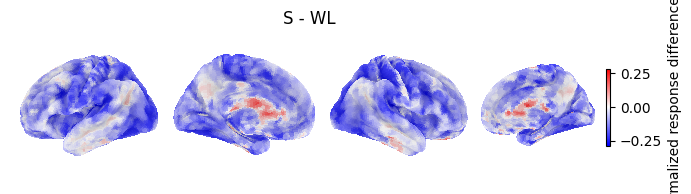

In [8]:
# @title Plot
# @markdown Red: greater predicted response to A. Blue: greater response to B.

# Normalize responses to [0, 1] per vertex
r_min = responses.min(axis=0, keepdims=True)
r_max = responses.max(axis=0, keepdims=True)

responses_norm = (
    (responses - r_min) /
    np.maximum(r_max - r_min, 1e-8)
)

# Compute condition means and differences
mean_a = responses_norm[stimuli.condition.eq(condition_a)].mean(axis=0)
mean_b = responses_norm[stimuli.condition.eq(condition_b)].mean(axis=0)
difference = mean_a - mean_b

# Use the 95th percentile to emphasize differences
limit = max(
    float(np.percentile(np.abs(difference), 95)),
    1e-8
)

# Plot brain
plotter = PlotBrainNilearn(mesh="fsaverage5")
views = ["left", "medial_left", "right", "medial_right"]
fig, axes = plotter.get_fig_axes(views)

plotter.plot_surf(
    difference,
    axes=axes,
    views=views,
    cmap="bwr",
    vmin=-limit,
    vmax=limit,
    symmetric_cbar=True,
    threshold=None,
    colorbar=True,
    colorbar_title="Normalized response difference",
)

fig.suptitle(f"{condition_a} - {condition_b}")

# Save results
stimuli.to_csv(output / "stimuli.csv", index=False)

np.savez_compressed(
    output / "responses.npz",
    responses=responses,
    responses_norm=responses_norm,
    mean_a=mean_a,
    mean_b=mean_b,
    difference=difference,
    condition_a=condition_a,
    condition_b=condition_b,
)

fig.savefig(
    output / "difference.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()